
========== MODEL COEFFICIENTS ==========
sepal length (cm) : -0.2342562060810893
sepal width (cm) : 0.23591068760291722
petal length (cm) : 0.5343131254144076
Intercept: -0.16932012542922936

========== REGRESSION EQUATION ==========
y = -0.16932012542922936
+ -0.2342562060810893 * sepal length (cm)
+ 0.23591068760291722 * sepal width (cm)
+ 0.5343131254144076 * petal length (cm)

========== MODEL EVALUATION ==========
Mean Squared Error: 0.04633260332576445
Root Mean Squared Error: 0.215250094833346
R2 Score: 0.9271105193357898

========== ACTUAL VS PREDICTED ==========
   actual  predicted
0     1.2   1.573539
1     0.3   0.300212
2     2.3   2.327035
3     1.5   1.513693
4     1.4   1.462991
5     0.4   0.169262
6     1.3   1.126513
7     2.3   1.670632
8     1.5   1.301704
9     1.2   1.192774


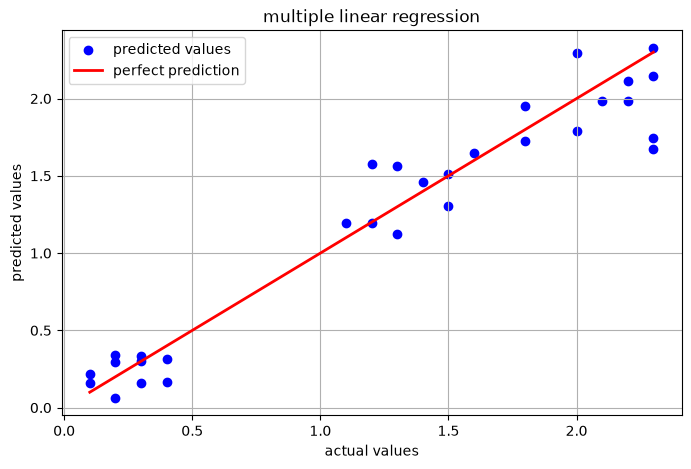

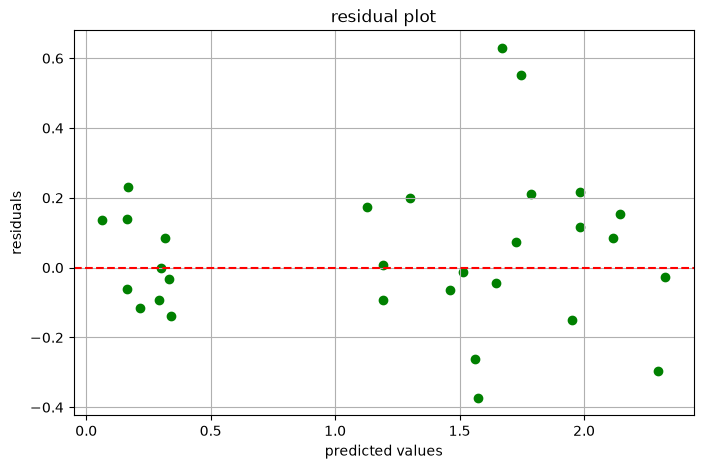


========== NEW PREDICTION ==========
predicted petal width: 1.5372837652578208

========== PROGRAM COMPLETED ==========


In [1]:

# ==========================================
# MULTIPLE LINEAR REGRESSION
# ==========================================

# 1. Import Libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# 2. Load Dataset

iri = load_iris()

dat = pd.DataFrame(
    iri.data,
    columns=iri.feature_names
)

# 3. Select Independent and Dependent Variables

x = dat[
    [
        'sepal length (cm)',
        'sepal width (cm)',
        'petal length (cm)'
    ]
]

y = dat['petal width (cm)']

# 4. Split Dataset

xtr, xte, ytr, yte = train_test_split(
    x,
    y,
    test_size=0.2,
    random_state=42
)

# 5. Create Linear Regression Model

mod = LinearRegression()

# 6. Train Model

mod.fit(xtr, ytr)

# 7. Make Predictions

ypred = mod.predict(xte)

# 8. Display Coefficients

print("\n========== MODEL COEFFICIENTS ==========")

for i, col in enumerate(x.columns):
    print(col, ":", mod.coef_[i])

print("Intercept:", mod.intercept_)

# 9. Regression Equation

print("\n========== REGRESSION EQUATION ==========")

print("y =", mod.intercept_)

for i, col in enumerate(x.columns):
    print("+", mod.coef_[i], "*", col)

# 10. Model Evaluation

mse = mean_squared_error(yte, ypred)
rmse = np.sqrt(mse)
r2 = r2_score(yte, ypred)

print("\n========== MODEL EVALUATION ==========")

print("Mean Squared Error:", mse)
print("Root Mean Squared Error:", rmse)
print("R2 Score:", r2)

# 11. Actual vs Predicted Values

res = pd.DataFrame({
    'actual': yte.values,
    'predicted': ypred
})

print("\n========== ACTUAL VS PREDICTED ==========")
print(res.head(10))

# 12. Actual vs Predicted Graph

plt.figure(figsize=(8, 5))

plt.scatter(
    yte,
    ypred,
    color='blue',
    label='predicted values'
)

plt.plot(
    [yte.min(), yte.max()],
    [yte.min(), yte.max()],
    color='red',
    linewidth=2,
    label='perfect prediction'
)

plt.xlabel('actual values')
plt.ylabel('predicted values')
plt.title('multiple linear regression')
plt.legend()
plt.grid(True)
plt.show()

# 13. Residual Plot

err = yte.values - ypred

plt.figure(figsize=(8, 5))

plt.scatter(ypred, err, color='green')

plt.axhline(y=0, color='red', linestyle='--')

plt.xlabel('predicted values')
plt.ylabel('residuals')
plt.title('residual plot')
plt.grid(True)
plt.show()

# 14. Predict New Values

new = pd.DataFrame({
    'sepal length (cm)': [6.0],
    'sepal width (cm)': [3.0],
    'petal length (cm)': [4.5]
})

pre = mod.predict(new)

print("\n========== NEW PREDICTION ==========")

print("predicted petal width:", pre[0])

# 15. Final Result

print("\n========== PROGRAM COMPLETED ==========")
